In [2]:
import polars as pl
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [22]:
counters = pl.read_csv("../../data/counters_raw.csv", try_parse_dates=True)
counters.head()

,operator_name,domain_name,domain_id,counter_site,counter_site_id,counter_serial,longitude,latitude,timezone,iso_timestamp,channels_in,channels_out,channels_unknown,channels_all,site_temperature,site_rain_accumulation,site_snow_accumulation
i64,str,str,i64,str,i64,str,f64,f64,str,"datetime[μs, UTC]",f64,f64,str,i64,f64,f64,str
0,"""Eco Counter GmbH""","""Stadt Tübingen""",667,"""Fuß- & Radtunnel Südportal - D…",100003358,"""YTH24052174""",9.04806,48.518,"""(UTC+01:00) Europe/Paris DST""",2020-12-31 23:00:00 UTC,4.0,1.0,null,5,0.0,0.0,null
1,"""Eco Counter GmbH""","""Stadt Tübingen""",667,"""Fuß- & Radtunnel Südportal - D…",100003358,"""YTH24052174""",9.04806,48.518,"""(UTC+01:00) Europe/Paris DST""",2021-01-01 00:00:00 UTC,2.0,0.0,null,2,0.0,0.0,null
2,"""Eco Counter GmbH""","""Stadt Tübingen""",667,"""Fuß- & Radtunnel Südportal - D…",100003358,"""YTH24052174""",9.04806,48.518,"""(UTC+01:00) Europe/Paris DST""",2021-01-01 01:00:00 UTC,1.0,0.0,null,1,0.0,0.0,null
3,"""Eco Counter GmbH""","""Stadt Tübingen""",667,"""Fuß- & Radtunnel Südportal - D…",100003358,"""YTH24052174""",9.04806,48.518,"""(UTC+01:00) Europe/Paris DST""",2021-01-01 02:00:00 UTC,2.0,0.0,null,2,0.0,0.0,null
4,"""Eco Counter GmbH""","""Stadt Tübingen""",667,"""Fuß- & Radtunnel Südportal - D…",100003358,"""YTH24052174""",9.04806,48.518,"""(UTC+01:00) Europe/Paris DST""",2021-01-01 03:00:00 UTC,0.0,0.0,null,0,0.0,0.0,null


In [4]:
min_max_dates = (
    counters.group_by(pl.col("counter_site_id"))
    .agg(
        pl.col("datetime").min().alias("start"),
        pl.col("datetime").max().alias("end")
    )
)
min_max_dates.describe()

statistic,counter_site_id,start,end
str,f64,str,str
"""count""",181.0,"""181""","""181"""
"""null_count""",0.0,"""0""","""0"""
"""mean""",2.2932e8,"""2022-08-31 23:52:42.430939+00:…","""2026-10-13 12:30:09.944751+00:…"
"""std""",9.5880e7,null,null
"""min""",1.00003358e8,"""2020-12-31 23:00:00+00:00""","""2023-03-13 22:00:00+00:00"""
"""25%""",1.00056853e8,"""2020-12-31 23:00:00+00:00""","""2026-10-31 22:00:00+00:00"""
"""50%""",3.00020056e8,"""2021-05-10 22:00:00+00:00""","""2026-10-31 22:00:00+00:00"""
"""75%""",3.00042289e8,"""2024-04-22 10:00:00+00:00""","""2026-10-31 22:00:00+00:00"""
"""max""",3.00069829e8,"""2026-06-10 12:00:00+00:00""","""2026-10-31 22:00:00+00:00"""


In [5]:
min_max_dates

counter_site_id,start,end
i64,"datetime[μs, UTC]","datetime[μs, UTC]"
300026107,2022-07-20 22:00:00 UTC,2026-10-31 22:00:00 UTC
300038412,2023-12-20 10:00:00 UTC,2026-10-31 22:00:00 UTC
100013457,2020-12-31 23:00:00 UTC,2026-10-30 03:00:00 UTC
300031079,2023-03-23 10:00:00 UTC,2026-10-31 22:00:00 UTC
300014844,2020-12-31 23:00:00 UTC,2026-10-31 22:00:00 UTC
…,…,…
300038236,2023-12-15 08:00:00 UTC,2026-10-31 22:00:00 UTC
100003358,2020-12-31 23:00:00 UTC,2026-10-31 22:00:00 UTC
100048812,2020-12-31 23:00:00 UTC,2026-10-31 22:00:00 UTC


<Axes: xlabel='start', ylabel='end'>

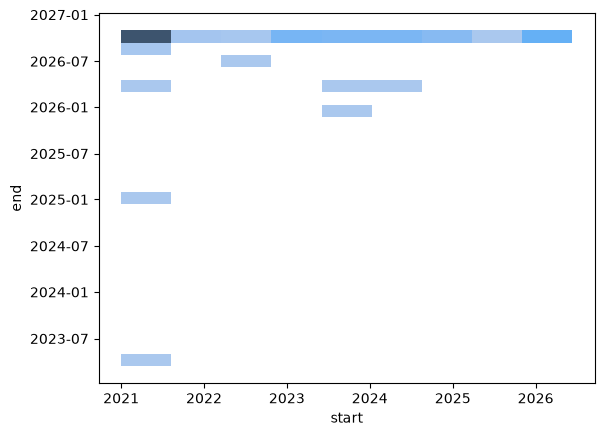

In [6]:
sns.histplot(data=min_max_dates.to_pandas(), x="start", y="end")

In [7]:
counters_with_enough_data = (
    min_max_dates.filter(
        pl.col("start") < pl.date(2021, 1, 1),
        pl.col("end") >= pl.date(2026, 10, 31)
    )
)

<Axes: ylabel='Probability'>

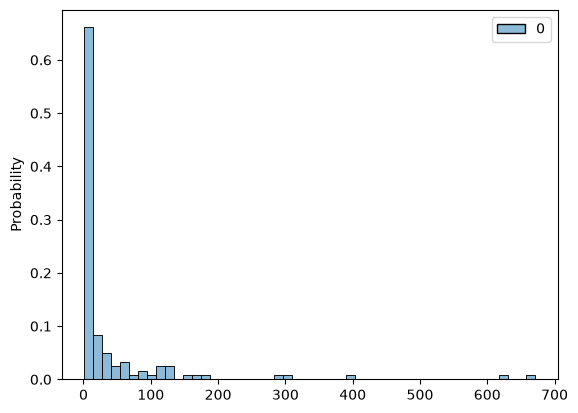

In [8]:
gaps_in_counters = (
    counters.group_by(
        pl.col("datetime").dt.date(),
        pl.col("counter_site_id"),
    )
    .agg(pl.col("channels_all").max())
    .filter(pl.col("channels_all") == 0)
    .group_by(pl.col("counter_site_id")).len()
)
sns.histplot(gaps_in_counters.select(pl.col("len")), stat="probability", bins=50)

In [9]:
gaps_in_counters.min()

counter_site_id,len
i64,u32
100003358,1


In [10]:
q = (
    gaps_in_counters
    .select(pl.col("len").quantile(0.95))
).item()
counters_with_gaps = (
    gaps_in_counters
    .filter(pl.col("len") > q)
)
counters_with_gaps

counter_site_id,len
i64,u32
100017862,181
100048814,671
100013034,621
300040059,287
100036542,401
100056853,307


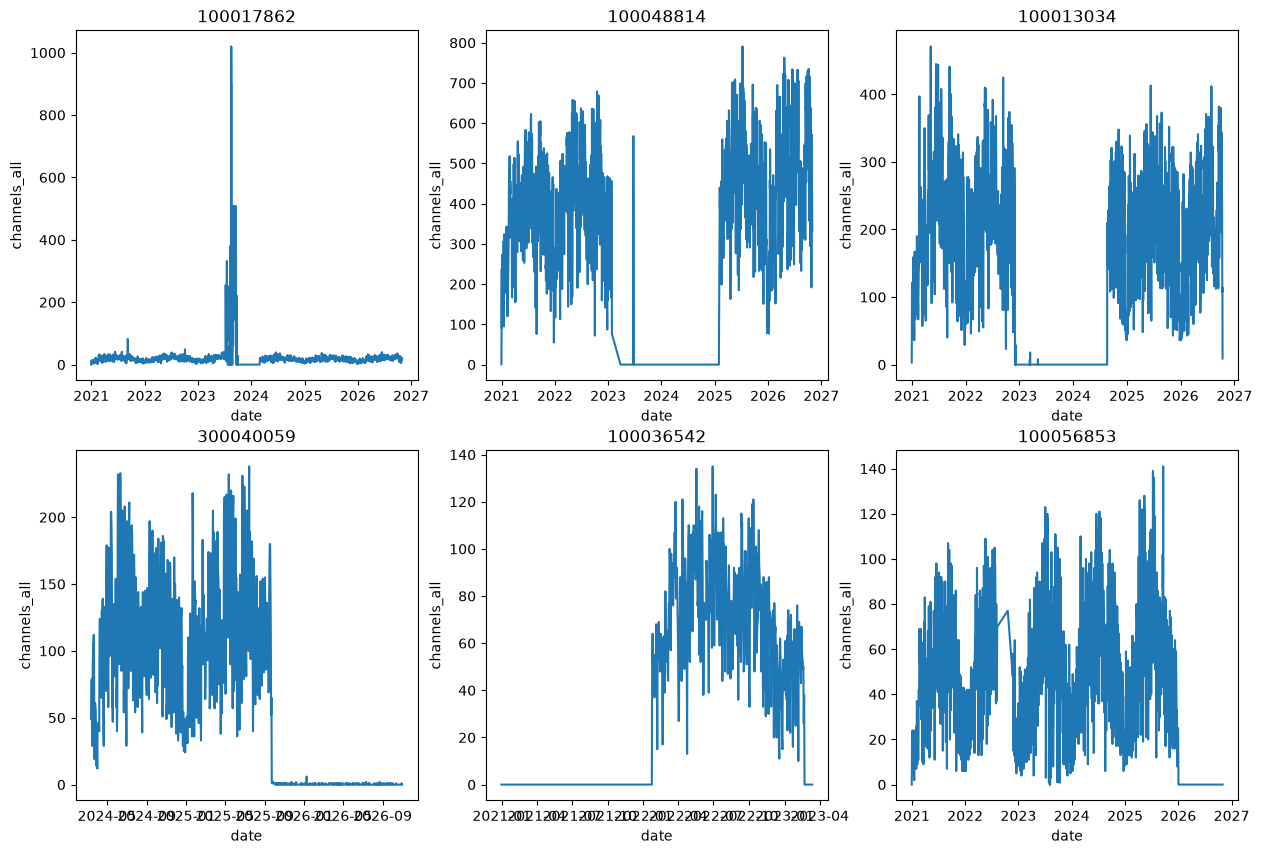

In [11]:
N = counters_with_gaps.shape[0]
fig, axs = plt.subplots(2, 3, figsize=(5*3, 5*2))

for i in range(N):
    ax = axs.flatten()[i]
    site_id, l = counters_with_gaps.row(i)
    station_daily_peaks = (counters.filter(pl.col("counter_site_id") == site_id)).group_by(pl.col("datetime").dt.date().alias("date")).agg(pl.col("channels_all").max())
    sns.lineplot(data=station_daily_peaks.to_pandas(), x="date", y="channels_all", ax=ax)
    ax.set_title(site_id)

# Clearly some counters have significant gaps, and also outliers in the upper direction which are probably measuring errors

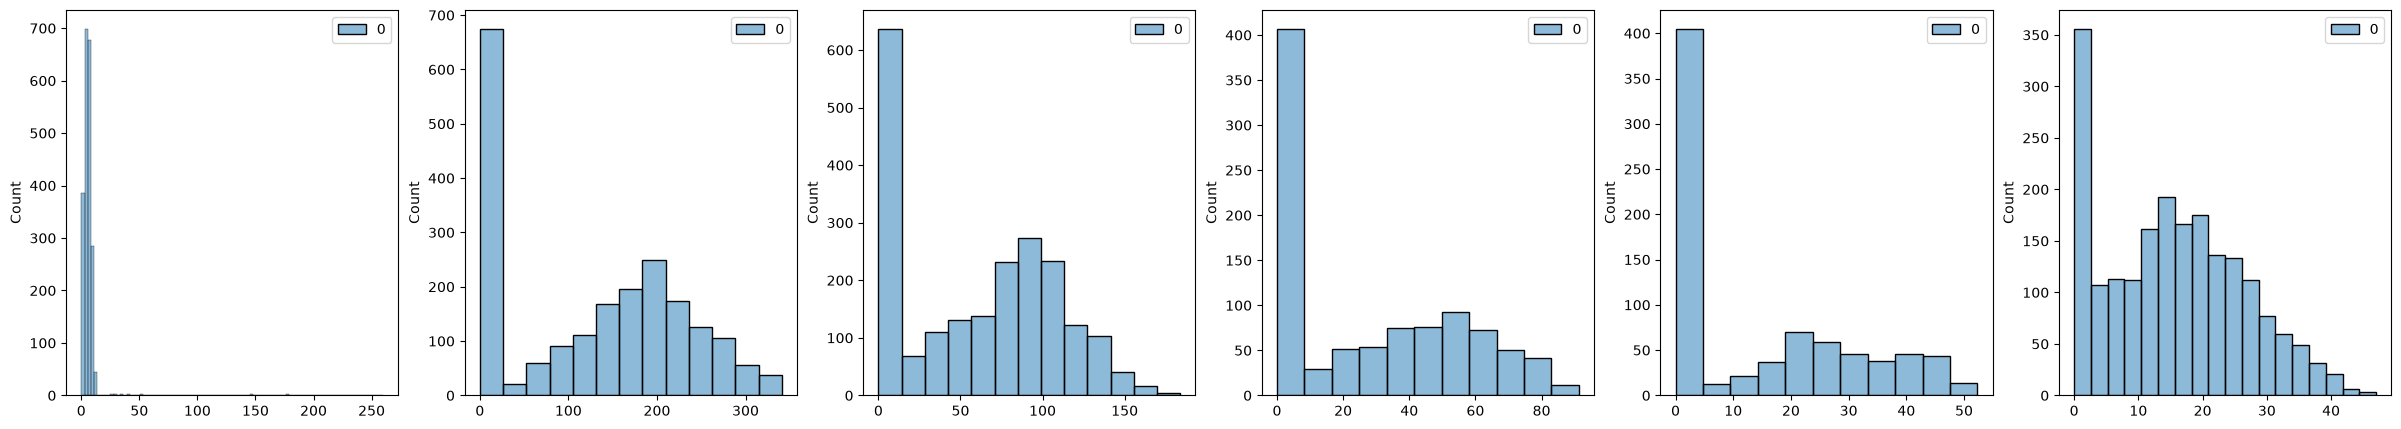

In [12]:
N = counters_with_gaps.shape[0]
fig, axs = plt.subplots(1, N, figsize=(5*N, 5))

for i in range(N):
    ax = axs[i]
    site_id, l = counters_with_gaps.row(i)
    station_daily_peaks = (
        counters
        .filter(pl.col("counter_site_id") == site_id)
        .group_by(by=pl.col("datetime").dt.date())
        .agg(pl.col("channels_all").mean())
        .select(pl.col("channels_all"))
    )
    sns.histplot(station_daily_peaks, ax=ax)

# The daily peaks seem to be normally distributed

In [13]:
gaps_in_counters.filter(pl.col("len") == 1)

counter_site_id,len
i64,u32
100061633,1
300042684,1
100035363,1
300017245,1
100042487,1
…,…
300029584,1
100057246,1
100056854,1


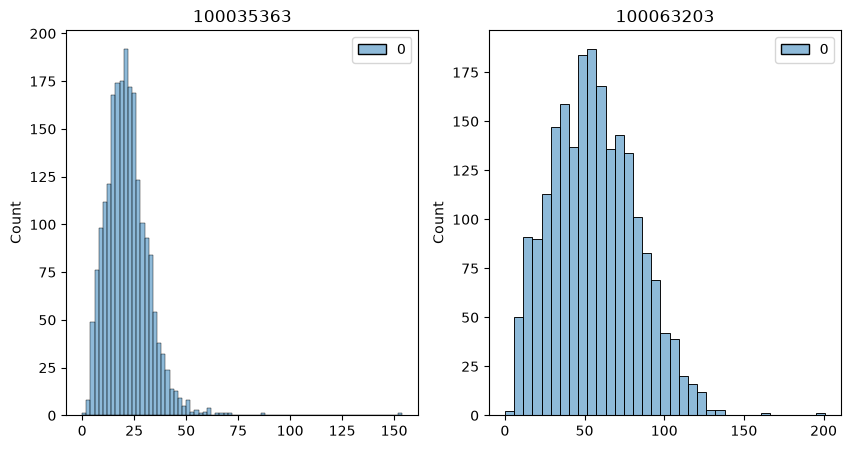

In [14]:
example_counters = [100035363, 100063203]
N = 2
fig, axs = plt.subplots(1, N, figsize=(5*N, 5))

for i in range(N):
    ax = axs[i]
    site_id = example_counters[i]
    station_channel_daily_peak = (
        counters
        .filter(pl.col("counter_site_id") == site_id)
        .group_by(by=pl.col("datetime").dt.date())
        .agg(pl.col("channels_all").max())
        .select(pl.col("channels_all"))
    )
    sns.histplot(station_channel_daily_peak, ax=ax)
    ax.set_title(site_id)

In [15]:
(
    counters
    .filter(pl.col("counter_site_id") == 100035363)
    .group_by(by=pl.col("datetime").dt.date())
    .agg(pl.col("channels_all").max())
    .filter(pl.col("channels_all") == 0)
)

by,channels_all
date,i64
2020-12-31,0


<Axes: ylabel='Count'>

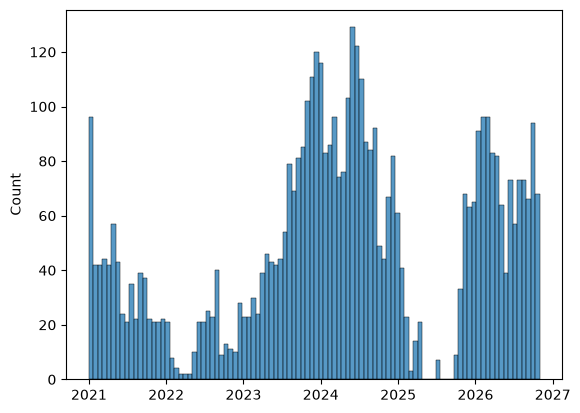

In [16]:
zero_days = (
    counters.group_by(
        pl.col("datetime").dt.date(),
        pl.col("counter_site_id"),
    )
    .agg(pl.col("channels_all").max())
    .filter(pl.col("channels_all") == 0)
)
sns.histplot(zero_days["datetime"], bins=100)

In [17]:
daily_peaks = (
    counters.group_by(
        pl.col("datetime").dt.date(),
        pl.col("counter_site_id"),
    )
    .agg(pl.col("channels_all").max())
)
daily_peaks

datetime,counter_site_id,channels_all
date,i64,i64
2025-08-12,300018447,205
2024-04-10,100003358,379
2025-05-04,300016792,115
2021-09-18,100059187,92
2024-05-04,100060133,88
…,…,…
2026-10-24,100042618,92
2026-04-02,100057246,135
2023-07-16,100063206,107


<Axes: xlabel='datetime'>

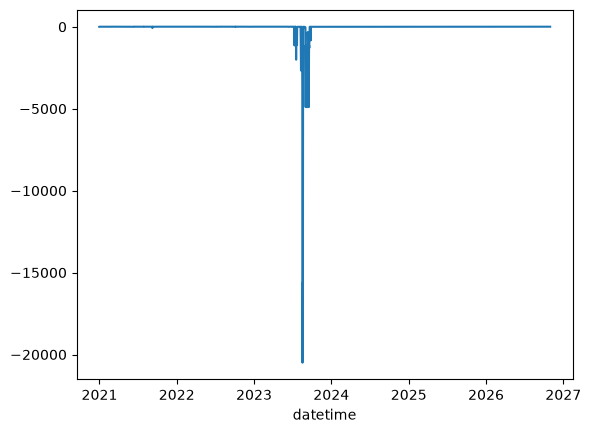

In [19]:
from sklearn.covariance import EllipticEnvelope

counter_id_with_outliers = 100017862

dpo = daily_peaks.filter(pl.col("counter_site_id") == counter_id_with_outliers)


cov = EllipticEnvelope(random_state=0)
labels = cov.fit_predict(dpo[["channels_all"]])

sns.lineplot(x=dpo["datetime"], y=cov.decision_function(dpo[["channels_all"]]))

,datetime,counter_site_id,channels_all
0,2022-04-30,100017862,15
1,2022-11-25,100017862,19
2,2026-08-21,100017862,13
3,2023-05-17,100017862,21
4,2024-08-18,100017862,6
...,...,...,...
2126,2026-02-16,100017862,8
2127,2022-04-23,100017862,17
2128,2024-12-19,100017862,11
2129,2025-07-14,100017862,26


<Axes: xlabel='datetime'>

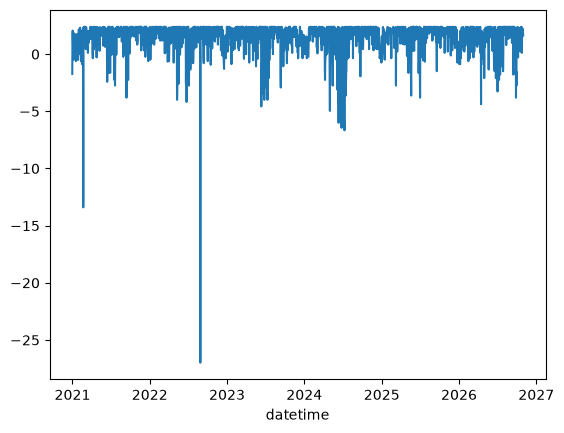

In [20]:

counter_id_with_outliers = 100063203

dp = daily_peaks.filter(pl.col("counter_site_id") == counter_id_with_outliers)


cov = EllipticEnvelope(random_state=0)
labels = cov.fit_predict(dp[["channels_all"]])
sns.lineplot(x=dp["datetime"], y=cov.decision_function(dp[["channels_all"]]))

In [174]:
dp.count()

datetime,counter_site_id,channels_all
u32,u32,u32
2131,2131,2131
